# Week 5 — disease-labelled CNN comparison and 1-D Grad-CAM

**Scope.** This notebook compares the preserved Week 4 disease-labelled CNN checkpoint with the existing Week 5 ResNet-1D architecture, retrained with the *correct* target. Positive means an exact match to at least one of the 19 selected ICD-10 codes in `Data/DiseaseCode.csv`; negative means no selected-code match, **not** normal ECG or free of all cardiovascular disease. The original `NoteBooks/Week5/dataset.py` and `experiment_runner.py` use ECG-statement labels and record-level splitting; they are not executed here. The Week 4 notebook and checkpoint remain unchanged.

All models use the same first 5,000 samples, per-present-lead z-scoring, anatomical lead mapping, patient split, and validation set. Baseline is a fixed existing checkpoint. ResNet candidates differ only in class weighting. We select each candidate's checkpoint by *unweighted* validation cross entropy; compare candidates using average precision (AP), recall and specificity at fixed threshold 0.5. A candidate is promoted only if its AP exceeds the Week 4 baseline, its recall is no lower, and its specificity is at least 0.5. This rule is defined before looking at new results. The same validation set is used for selection and reporting, so all comparisons are exploratory; the frozen test group is not loaded or evaluated. We do not adjust the threshold on validation.

Grad-CAM follows [Selvaraju et al., ICCV 2017](https://openaccess.thecvf.com/content_ICCV_2017/papers/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.pdf), adapted from two spatial image dimensions to one temporal ECG dimension. Visual inspection alone does not establish explanation validity; see [Adebayo et al., NeurIPS 2018](https://proceedings.neurips.cc/paper/8160-sanity-checks-for-saliency-maps.pdf).

In [1]:
from pathlib import Path
import os, sys, random, platform, importlib.util
import numpy as np, pandas as pd, wfdb, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,recall_score,
                             f1_score,roc_auc_score,average_precision_score,confusion_matrix)
from IPython.display import display

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').is_file())
DATA=ROOT/'Data'; RECORDS=ROOT/'Child_ECG/Child_ecg'; W4=ROOT/'NoteBooks/Week4'; W5=ROOT/'NoteBooks/Week5'
OUT=W5/'disease_labelled'; OUT.mkdir(exist_ok=True)
SEED=42; FS=500; N_SAMPLES=5000; BATCH_SIZE=32; MAX_EPOCHS=8; PATIENCE=3; LR=3e-4; WEIGHT_DECAY=1e-4
assert Path(sys.executable).resolve()==(ROOT/'venv/bin/python').resolve()
print('Python',platform.python_version(),sys.executable)
print('Torch',torch.__version__,'CUDA build',torch.version.cuda,'CUDA available',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU',torch.cuda.get_device_name(0))
print('WFDB',wfdb.__version__,'pandas',pd.__version__)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4,os.cpu_count() or 1))
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic=True
        torch.backends.cudnn.benchmark=False
seed_all()
print('Execution device',DEVICE)

Python 3.13.5 /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python
Torch 2.6.0+cu124 CUDA build 12.4 CUDA available True
GPU NVIDIA GeForce RTX 3060 Laptop GPU
WFDB 4.3.1 pandas 2.3.3
Execution device cuda


## Dataset audit (training and validation patients only)

`Age` is recorded in days. `Sampling_point` is a count of samples at 500 Hz. For scientific comparison, the model sees the first 10 seconds even when the recording is longer. ICD tokens are split on semicolons with quote characters removed; qualifiers such as `(FO) Q21.1` remain part of the token. The reserved group is identified by patient ID only and excluded from the profiles below.

In [2]:
meta=pd.read_csv(DATA/'AttributesDictionary.csv')
disease=pd.read_csv(DATA/'DiseaseCode.csv')
selected_codes=set(disease.loc[disease['Disease Type']!='Other diseases(OD)','ICD-10 Code'].astype(str).str.strip())
assert len(selected_codes)==19 and len(meta)==14190 and meta.ECG_ID.is_unique
def icd_tokens(value): return [x.strip().strip("'\"").strip() for x in str(value).split(';') if x.strip()]
assert all(x.split('/')[-2]==pid for x,pid in zip(meta.Filename,meta.Patient_ID))
patients=sorted(meta.Patient_ID.unique().tolist()); random.Random(SEED).shuffle(patients)
ntrain=int(.70*len(patients)); nval=int(.15*len(patients))
train_ids=set(patients[:ntrain]); val_ids=set(patients[ntrain:ntrain+nval]); reserved_ids=set(patients[ntrain+nval:])
assert not (train_ids&val_ids or train_ids&reserved_ids or val_ids&reserved_ids)
train_df=meta.loc[meta.Patient_ID.isin(train_ids)].reset_index(drop=True)
val_df=meta.loc[meta.Patient_ID.isin(val_ids)].reset_index(drop=True)
for frame in [train_df,val_df]:
    frame['codes']=frame['ICD-10 code'].map(icd_tokens)
    frame['target']=frame.codes.map(lambda xs:int(bool(set(xs)&selected_codes)))
profile_df=pd.concat([train_df,val_df],ignore_index=True)
assert (len(train_df),len(val_df))==(9943,2169)
assert (train_df.target.sum(),val_df.target.sum())==(2595,583)
profile_df['age_years']=profile_df.Age.str.extract(r'^(\d+)d$')[0].astype(float)/365.25
assert profile_df.age_years.notna().all()
print('Patient split: train',len(train_ids),'validation',len(val_ids),'reserved',len(reserved_ids))
print('Record split: train',len(train_df),'validation',len(val_df),'(reserved records not profiled)')
print('Target counts train',train_df.target.value_counts().sort_index().to_dict(),
      'validation',val_df.target.value_counts().sort_index().to_dict())
print('Lead counts (train+validation)',profile_df.Lead.value_counts().sort_index().to_dict())
print('Length seconds quantiles (train+validation)',(profile_df.Sampling_point/FS).quantile([0,.25,.5,.75,.9,1]).to_dict())
print('Records shorter than 10 s:',int((profile_df.Sampling_point<N_SAMPLES).sum()))
print('Records longer than 10 s:',int((profile_df.Sampling_point>N_SAMPLES).sum()))
print('Age years quantiles',profile_df.age_years.quantile([0,.1,.25,.5,.75,.9,1]).round(2).to_dict())
code_counts={code:int(profile_df.codes.map(lambda xs:code in xs).sum()) for code in sorted(selected_codes)}
display(pd.Series(code_counts,name='records with selected code').sort_values(ascending=False).to_frame())
print('Code counts can overlap because a record may have multiple ICD diagnoses.')
display(pd.crosstab(profile_df.Lead,profile_df.target,rownames=['Leads'],colnames=['Selected-code target']))

Patient split: train 8150 validation 1746 reserved 1747
Record split: train 9943 validation 2169 (reserved records not profiled)
Target counts train {0: 7348, 1: 2595} validation {0: 1586, 1: 583}
Lead counts (train+validation) {9: 1579, 12: 10533}
Length seconds quantiles (train+validation) {0.0: 5.0, 0.25: 21.0, 0.5: 30.0, 0.75: 30.0, 0.9: 30.0, 1.0: 120.0}
Records shorter than 10 s: 7
Records longer than 10 s: 12092
Age years quantiles {0.0: 0.0, 0.1: 1.25, 0.25: 4.25, 0.5: 8.59, 0.75: 12.38, 0.9: 14.01, 1.0: 14.99}


,records with selected code
Q21.0,919
Q21.1,798
(FO) Q21.1,524
Q25.0,294
(V) I40.0,273
M30.3,159
I51.4,141
Q21.3,82
(F) I40.0,80
(OSD) Q21.1,75


Code counts can overlap because a record may have multiple ICD diagnoses.


Selected-code target,0,1
Leads,,
9,789,790
12,8145,2388


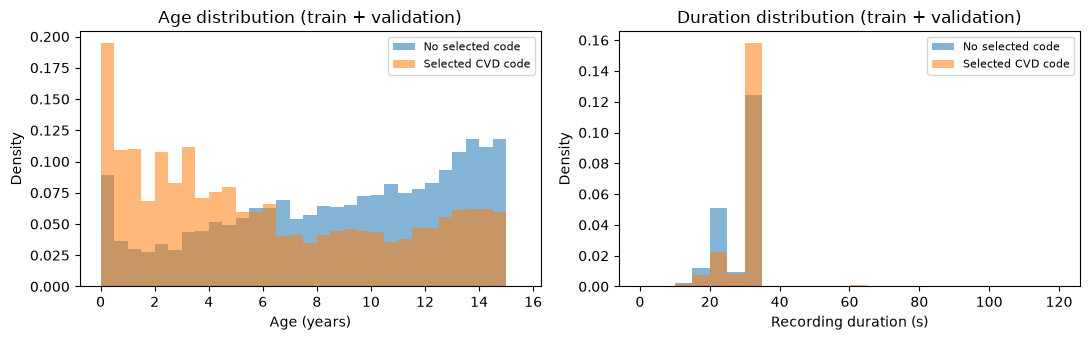

9-lead example header: fs=500, sig_len=9000, leads=['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V3', 'V5']
12-lead example header: fs=500, sig_len=15000, leads=['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
for target,label in [(0,'No selected code'),(1,'Selected CVD code')]:
    v=profile_df.loc[profile_df.target==target]
    ax[0].hist(v.age_years,bins=np.arange(0,16,.5),density=True,alpha=.55,label=label)
    ax[1].hist(v.Sampling_point/FS,bins=np.arange(0,125,5),density=True,alpha=.55,label=label)
ax[0].set(xlabel='Age (years)',ylabel='Density',title='Age distribution (train + validation)')
ax[1].set(xlabel='Recording duration (s)',ylabel='Density',title='Duration distribution (train + validation)')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
for leads in [9,12]:
    row=profile_df.loc[profile_df.Lead==leads].iloc[0]
    header=wfdb.rdheader(str(RECORDS/row.Filename))
    print(f'{leads}-lead example header: fs={header.fs}, sig_len={header.sig_len}, leads={header.sig_name}')

## Comparable signal preprocessing and models

The Week 4 architecture has one 5-sample temporal convolution, max pooling, then a flattened linear classifier. Its final classifier depends on absolute position in the 10-second crop and it has no learned hierarchy of longer waveform patterns. The existing Week 5 `ResNet1D` provides deeper receptive fields and global pooling, making a time-shifted pattern less dependent on a fixed position. This is an architectural rationale, not evidence of improvement. Both models use the same signal loader below. Nine-lead records omit V2, V4, V6; those slots are zero after mapping by header lead names. Per-present-lead z-scoring removes absolute voltage information.

In [4]:
LEADS=['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']
LEAD_INDEX={lead:i for i,lead in enumerate(LEADS)}
length_by_file=dict(zip(profile_df.Filename,profile_df.Sampling_point))
class CVDRecordDataset(Dataset):
    def __init__(self,frame): self.frame=frame[['Filename','target']].reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        signal,fields=wfdb.rdsamp(str(RECORDS/row.Filename),sampto=min(N_SAMPLES,int(length_by_file[row.Filename])))
        assert fields['fs']==FS and np.isfinite(signal).all()
        output=np.zeros((12,N_SAMPLES),dtype=np.float32)
        for j,lead in enumerate(fields['sig_name']):
            key=lead.upper(); assert key in LEAD_INDEX
            x=signal[:,j].astype(np.float32); std=x.std()
            output[LEAD_INDEX[key],:len(x)]=(x-x.mean())/std if std>1e-8 else 0
        return torch.from_numpy(output),int(row.target)

train_data=CVDRecordDataset(train_df); val_data=CVDRecordDataset(val_df)
train_loader=DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True,num_workers=2)
val_loader=DataLoader(val_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
def import_module(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    module=importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
    return module
SimpleECGModel=import_module('week4_original_arch',W4/'pytorch_starter.py').SimpleECGModel
ResNet1D=import_module('week5_original_arch',W5/'models.py').ResNet1D
seed_all(); baseline=SimpleECGModel(num_classes=2).to(DEVICE)
with torch.no_grad(): baseline(torch.zeros(1,12,N_SAMPLES,device=DEVICE))
base_saved=torch.load(W4/'Week4_CVD_Binary_CNN_best.pth',map_location=DEVICE,weights_only=False)
assert base_saved['target']=='Any exact match to the 19 selected codes in Data/DiseaseCode.csv'
assert base_saved['lead_order']==LEADS and base_saved['input_samples']==N_SAMPLES
baseline.load_state_dict(base_saved['model_state_dict']); baseline.eval()
print('Week 4 parameters',sum(p.numel() for p in baseline.parameters()))
probe=ResNet1D(num_classes=2)
print('Week 5 ResNet parameters',sum(p.numel() for p in probe.parameters()))
del probe

Week 4 parameters 80978
Week 5 ResNet parameters 548930


## Validation metrics and baseline reproduction

All scores are at the unchanged 0.5 threshold. AP and AUROC use continuous scores. Confusion matrix convention is `[[TN, FP], [FN, TP]]`. The baseline checkpoint was selected previously by Week 4 validation loss. Re-evaluating it here checks that the data path and preprocessing really match.

In [5]:
def metrics(y,p):
    pred=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),
                precision=precision_score(y,pred,zero_division=0),sensitivity=recall_score(y,pred,zero_division=0),
                specificity=tn/(tn+fp),f1=f1_score(y,pred,zero_division=0),
                auroc=roc_auc_score(y,p),average_precision=average_precision_score(y,p),
                tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

def run_epoch(model,loader,optimizer=None,train_loss_fn=None):
    training=optimizer is not None
    model.train(training)
    y_all=[]; p_all=[]; total_eval_loss=0.; total_train_loss=0.
    for x,y in loader:
        x=x.to(DEVICE); y=y.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits=model(x)
            eval_loss=F.cross_entropy(logits,y)
            if training:
                loss=train_loss_fn(logits,y)
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                total_train_loss+=float(loss.item())*len(y)
        total_eval_loss+=float(eval_loss.item())*len(y)
        y_all.extend(y.cpu().tolist())
        p_all.extend(torch.softmax(logits.detach(),dim=1)[:,1].cpu().tolist())
    n=len(loader.dataset)
    return total_eval_loss/n,np.asarray(y_all),np.asarray(p_all),total_train_loss/n if training else None

base_loss,base_y,base_p,_=run_epoch(baseline,val_loader)
base_metrics=metrics(base_y,base_p)
assert (base_metrics['tn'],base_metrics['fp'],base_metrics['fn'],base_metrics['tp'])==(1433,153,401,182), 'Week 4 baseline reproduction failed.'
print('Week 4 validation loss',round(base_loss,4))
print(pd.Series(base_metrics).round(4).to_string())

Week 4 validation loss 0.5526
accuracy                0.7446
balanced_accuracy       0.6079
precision               0.5433
sensitivity             0.3122
specificity             0.9035
f1                      0.3965
auroc                   0.6763
average_precision       0.4574
tn                   1433.0000
fp                    153.0000
fn                    401.0000
tp                    182.0000


## Corrected-label ResNet experiments

These models are trained from scratch. The only difference is whether training cross entropy uses inverse-frequency weights calculated on **training records only**. Validation loss is always unweighted for comparable checkpoint selection. Early stop after three non-improving epochs, up to eight epochs. Same seed, optimizer, learning rate, weight decay, batch size, input, and patient split. The existing Week 5 experiment runner is not used.

In [6]:
train_counts=np.bincount(train_df.target.to_numpy(),minlength=2)
class_weights=torch.as_tensor(len(train_df)/(2*train_counts),dtype=torch.float32,device=DEVICE)
print('Training class counts',train_counts.tolist(),'weights',class_weights.cpu().tolist())

def train_candidate(name,weighted):
    seed_all()
    net=ResNet1D(num_classes=2).to(DEVICE)
    optimizer=torch.optim.Adam(net.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    weight=class_weights if weighted else None
    loss_fn=lambda logits,y:F.cross_entropy(logits,y,weight=weight)
    path=OUT/f'{name}_best.pth'; history=[]; best_loss=float('inf'); best_epoch=0; no_improve=0
    for epoch in range(1,MAX_EPOCHS+1):
        _,_,_,train_loss=run_epoch(net,train_loader,optimizer,loss_fn)
        val_loss,y,p,_=run_epoch(net,val_loader)
        m=metrics(y,p)
        history.append(dict(epoch=epoch,train_loss=train_loss,val_loss=val_loss,
                            val_ap=m['average_precision'],val_auroc=m['auroc'],
                            val_sensitivity=m['sensitivity'],val_specificity=m['specificity']))
        print(f'{name} epoch {epoch}: train loss {train_loss:.4f} val loss {val_loss:.4f} '
              f'AP {m["average_precision"]:.4f} AUROC {m["auroc"]:.4f} '
              f'sens {m["sensitivity"]:.4f} spec {m["specificity"]:.4f}',flush=True)
        if val_loss<best_loss-1e-5:
            best_loss=val_loss; best_epoch=epoch; no_improve=0
            torch.save({'model_state_dict':net.state_dict(),'epoch':epoch,'validation_loss':val_loss,
                        'weighted':weighted,'train_class_weights':class_weights.cpu().tolist() if weighted else None,
                        'seed':SEED,'architecture':'NoteBooks/Week5/models.py:ResNet1D',
                        'target':'Any exact match to 19 selected codes in Data/DiseaseCode.csv',
                        'lead_order':LEADS,'input_samples':N_SAMPLES,'lr':LR,'weight_decay':WEIGHT_DECAY},path)
        else:
            no_improve+=1
            if no_improve>=PATIENCE: break
    saved=torch.load(path,map_location=DEVICE,weights_only=False)
    net.load_state_dict(saved['model_state_dict']); net.eval()
    loss,y,p,_=run_epoch(net,val_loader)
    return dict(model=net,path=path,history=pd.DataFrame(history),best_epoch=best_epoch,
                loss=loss,y=y,p=p,metrics=metrics(y,p))

runs={}
for name,weighted in [('resnet_unweighted',False),('resnet_weighted',True)]:
    runs[name]=train_candidate(name,weighted)
print('Candidate training complete.')

Training class counts [7348, 2595] weights [0.6765786409378052, 1.915799617767334]


resnet_unweighted epoch 1: train loss 0.5121 val loss 0.4592 AP 0.6440 AUROC 0.7941 sens 0.4134 spec 0.9256


resnet_unweighted epoch 2: train loss 0.4861 val loss 0.4638 AP 0.6405 AUROC 0.7889 sens 0.3842 spec 0.9496


resnet_unweighted epoch 3: train loss 0.4749 val loss 0.4495 AP 0.6802 AUROC 0.8097 sens 0.4374 spec 0.9426


resnet_unweighted epoch 4: train loss 0.4672 val loss 0.4490 AP 0.6774 AUROC 0.8124 sens 0.4305 spec 0.9451


resnet_unweighted epoch 5: train loss 0.4569 val loss 0.4543 AP 0.6842 AUROC 0.8107 sens 0.3173 spec 0.9754


... (4 outputs left out)

resnet_weighted epoch 2: train loss 0.5845 val loss 0.5873 AP 0.6556 AUROC 0.7845 sens 0.7341 spec 0.6892


resnet_weighted epoch 3: train loss 0.5729 val loss 0.5727 AP 0.6862 AUROC 0.8153 sens 0.7684 spec 0.7049


resnet_weighted epoch 4: train loss 0.5648 val loss 0.6308 AP 0.6657 AUROC 0.8053 sens 0.8268 spec 0.5921


Candidate training complete.


## Comparison and model selection

The baseline and both candidates share validation records and preprocessing. This is a comparison on one validation partition and one seed; it is not a statistically confirmed gain. AP is the primary ranking metric because the positive class is a minority; sensitivity and specificity are guardrails. The positive prevalence is the random-ranking AP reference, and always-negative accuracy is the majority-class reference.

,epoch,loss,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,auroc,average_precision,tn,fp,fn,tp
week4_baseline,1.0,0.5526,0.7446,0.6079,0.5433,0.3122,0.9035,0.3965,0.6763,0.4574,1433.0,153.0,401.0,182.0
resnet_unweighted,7.0,0.4359,0.8165,0.6993,0.7761,0.4460,0.9527,0.5664,0.8144,0.6923,1511.0,75.0,323.0,260.0
resnet_weighted,1.0,0.5338,0.7473,0.7220,0.5236,0.6672,0.7768,0.5867,0.7971,0.6548,1232.0,354.0,194.0,389.0


Validation prevalence: 0.2688 always-negative accuracy: 0.7312
Selected by prespecified validation rule: resnet_unweighted


,epoch,train_loss,val_loss,val_ap,val_auroc,val_sensitivity,val_specificity
0,1,0.512100,0.459200,0.644000,0.794100,0.413400,0.925600
1,2,0.486100,0.463800,0.640500,0.788900,0.384200,0.949600
2,3,0.474900,0.449500,0.680200,0.809700,0.437400,0.942600
3,4,0.467200,0.449000,0.677400,0.812400,0.430500,0.945100
4,5,0.456900,0.454300,0.684200,0.810700,0.317300,0.975400
5,6,0.454400,0.437700,0.687000,0.815800,0.397900,0.956500
6,7,0.448100,0.435900,0.692300,0.814400,0.446000,0.952700
7,8,0.436300,0.439700,0.689400,0.812900,0.533400,0.907300


,epoch,train_loss,val_loss,val_ap,val_auroc,val_sensitivity,val_specificity
0,1,0.614400,0.533800,0.654800,0.797100,0.667200,0.776800
1,2,0.584500,0.587300,0.655600,0.784500,0.734100,0.689200
2,3,0.572900,0.572700,0.686200,0.815300,0.768400,0.704900
3,4,0.564800,0.630800,0.665700,0.805300,0.826800,0.592100


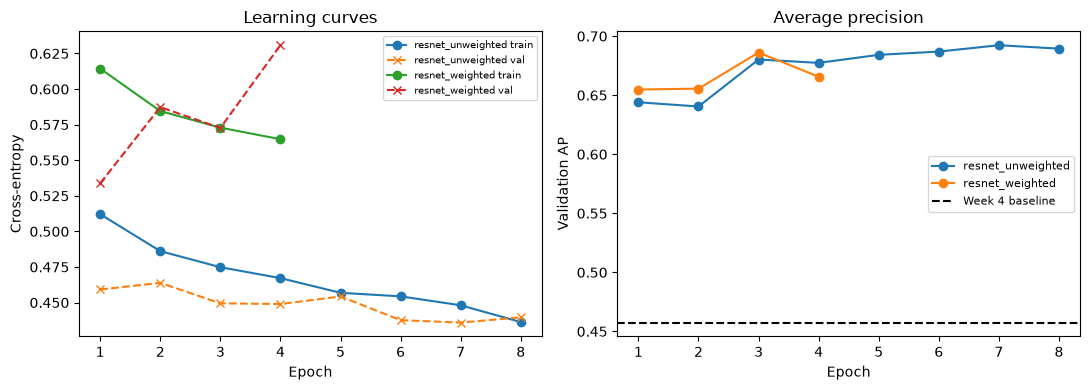

In [7]:
summary={'week4_baseline':dict(loss=base_loss,epoch=base_saved['epoch'],**base_metrics)}
for name,run in runs.items(): summary[name]=dict(loss=run['loss'],epoch=run['best_epoch'],**run['metrics'])
comparison=pd.DataFrame(summary).T
cols=['epoch','loss','accuracy','balanced_accuracy','precision','sensitivity','specificity','f1','auroc','average_precision','tn','fp','fn','tp']
display(comparison[cols].round(4))
print('Validation prevalence:',round(base_y.mean(),4),'always-negative accuracy:',round(1-base_y.mean(),4))
eligible=[name for name,run in runs.items() if run['metrics']['average_precision']>base_metrics['average_precision']
          and run['metrics']['sensitivity']>=base_metrics['sensitivity']
          and run['metrics']['specificity']>=.5]
selected=max(eligible,key=lambda n:runs[n]['metrics']['average_precision']) if eligible else 'week4_baseline'
selected_model=baseline if selected=='week4_baseline' else runs[selected]['model']
selected_y=base_y if selected=='week4_baseline' else runs[selected]['y']
selected_p=base_p if selected=='week4_baseline' else runs[selected]['p']
print('Selected by prespecified validation rule:',selected)
for name,run in runs.items(): display(run['history'].round(4).style.set_caption(name+' learning history'))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,run in runs.items():
    h=run['history'];ax[0].plot(h.epoch,h.train_loss,marker='o',label=name+' train')
    ax[0].plot(h.epoch,h.val_loss,marker='x',linestyle='--',label=name+' val')
    ax[1].plot(h.epoch,h.val_ap,marker='o',label=name)
ax[0].set(xlabel='Epoch',ylabel='Cross-entropy',title='Learning curves');ax[0].legend(fontsize=7)
ax[1].axhline(base_metrics['average_precision'],color='black',linestyle='--',label='Week 4 baseline')
ax[1].set(xlabel='Epoch',ylabel='Validation AP',title='Average precision');ax[1].legend(fontsize=8)
plt.tight_layout();plt.show()

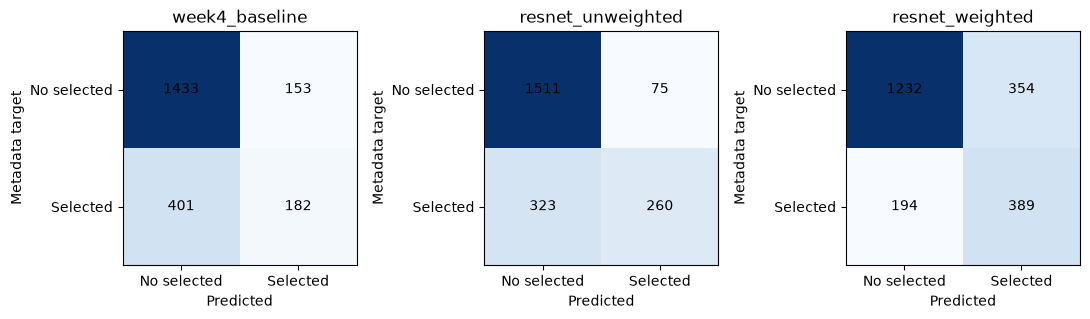

In [8]:
fig,axs=plt.subplots(1,3,figsize=(11,3.3))
for ax,(name,row) in zip(axs,comparison.iterrows()):
    cm=np.array([[row.tn,row.fp],[row.fn,row.tp]],dtype=int)
    ax.imshow(cm,cmap='Blues')
    for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No selected','Selected'],
           yticklabels=['No selected','Selected'],xlabel='Predicted',ylabel='Metadata target',title=name)
plt.tight_layout();plt.show()

## Temporal Grad-CAM on representative validation outcomes

For each available TP/TN/FP/FN category, choose the record with **median predicted positive score** within that category; this deterministic choice avoids hand-picking a visually attractive example. The class whose logit is explained is the **predicted class** (positive for TP/FP, negative for TN/FN). We weight each channel of the last convolution's activation by its time-averaged class gradient, sum across channels, apply ReLU, interpolate to 5,000 samples, and normalize per record. A heatmap is shared across leads because this Grad-CAM layer has already mixed lead channels; it does **not** give lead-specific importance. The displayed traces are z-scored model inputs. Heat is model attribution, not identified cardiac pathology.

In [9]:
def grad_cam_1d(model,x,layer,cls):
    state={}
    def hook(_module,_inputs,output):
        state['activation']=output.detach()
        output.register_hook(lambda grad:state.__setitem__('gradient',grad.detach()))
    handle=layer.register_forward_hook(hook)
    try:
        model.eval(); model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            xx=x.unsqueeze(0).to(DEVICE).requires_grad_(True)
            logits=model(xx); logits[0,cls].backward()
            a=state['activation'];g=state['gradient']
            weights=g.mean(dim=-1,keepdim=True)
            cam=F.relu((weights*a).sum(dim=1,keepdim=True))
            cam=F.interpolate(cam,size=N_SAMPLES,mode='linear',align_corners=False).squeeze().cpu().numpy()
            if cam.max()>cam.min():cam=(cam-cam.min())/(cam.max()-cam.min())
            else:cam=np.zeros_like(cam)
        return cam
    finally:
        handle.remove(); model.zero_grad(set_to_none=True)

cam_layer=selected_model.conv1 if selected=='week4_baseline' else selected_model.layer3[-1].conv2
pred=(selected_p>=.5).astype(int)
categories={'TP':(selected_y==1)&(pred==1),'TN':(selected_y==0)&(pred==0),
            'FP':(selected_y==0)&(pred==1),'FN':(selected_y==1)&(pred==0)}
examples={}
for cat,mask in categories.items():
    candidates=np.flatnonzero(mask)
    if len(candidates):
        idx=int(candidates[np.argmin(abs(selected_p[candidates]-np.median(selected_p[candidates])))])
        x,y=val_data[idx];cls=int(pred[idx]);cam=grad_cam_1d(selected_model,x,cam_layer,cls)
        examples[cat]=dict(index=idx,x=x.numpy(),y=y,p=float(selected_p[idx]),cls=cls,cam=cam)
print('Examples available:',list(examples))
example_summary=[]
for cat,e in examples.items():
    window=np.convolve(e['cam'],np.ones(FS)/FS,mode='valid')
    t=int(np.argmax(window))/FS
    example_summary.append(dict(outcome=cat,validation_index=e['index'],positive_score=e['p'],
                                explained_class=e['cls'],peak_1s_start=t,peak_1s_end=t+1,
                                cam_dynamic_range=float(e['cam'].max()-e['cam'].min())))
display(pd.DataFrame(example_summary).round(3))

Examples available: ['TP', 'TN', 'FP', 'FN']


,outcome,validation_index,positive_score,explained_class,peak_1s_start,peak_1s_end,cam_dynamic_range
0,TP,244,0.781,1,6.500,7.500,1.0
1,TN,1544,0.114,0,7.786,8.786,1.0
2,FP,778,0.609,1,1.914,2.914,1.0
3,FN,359,0.215,0,0.700,1.700,1.0


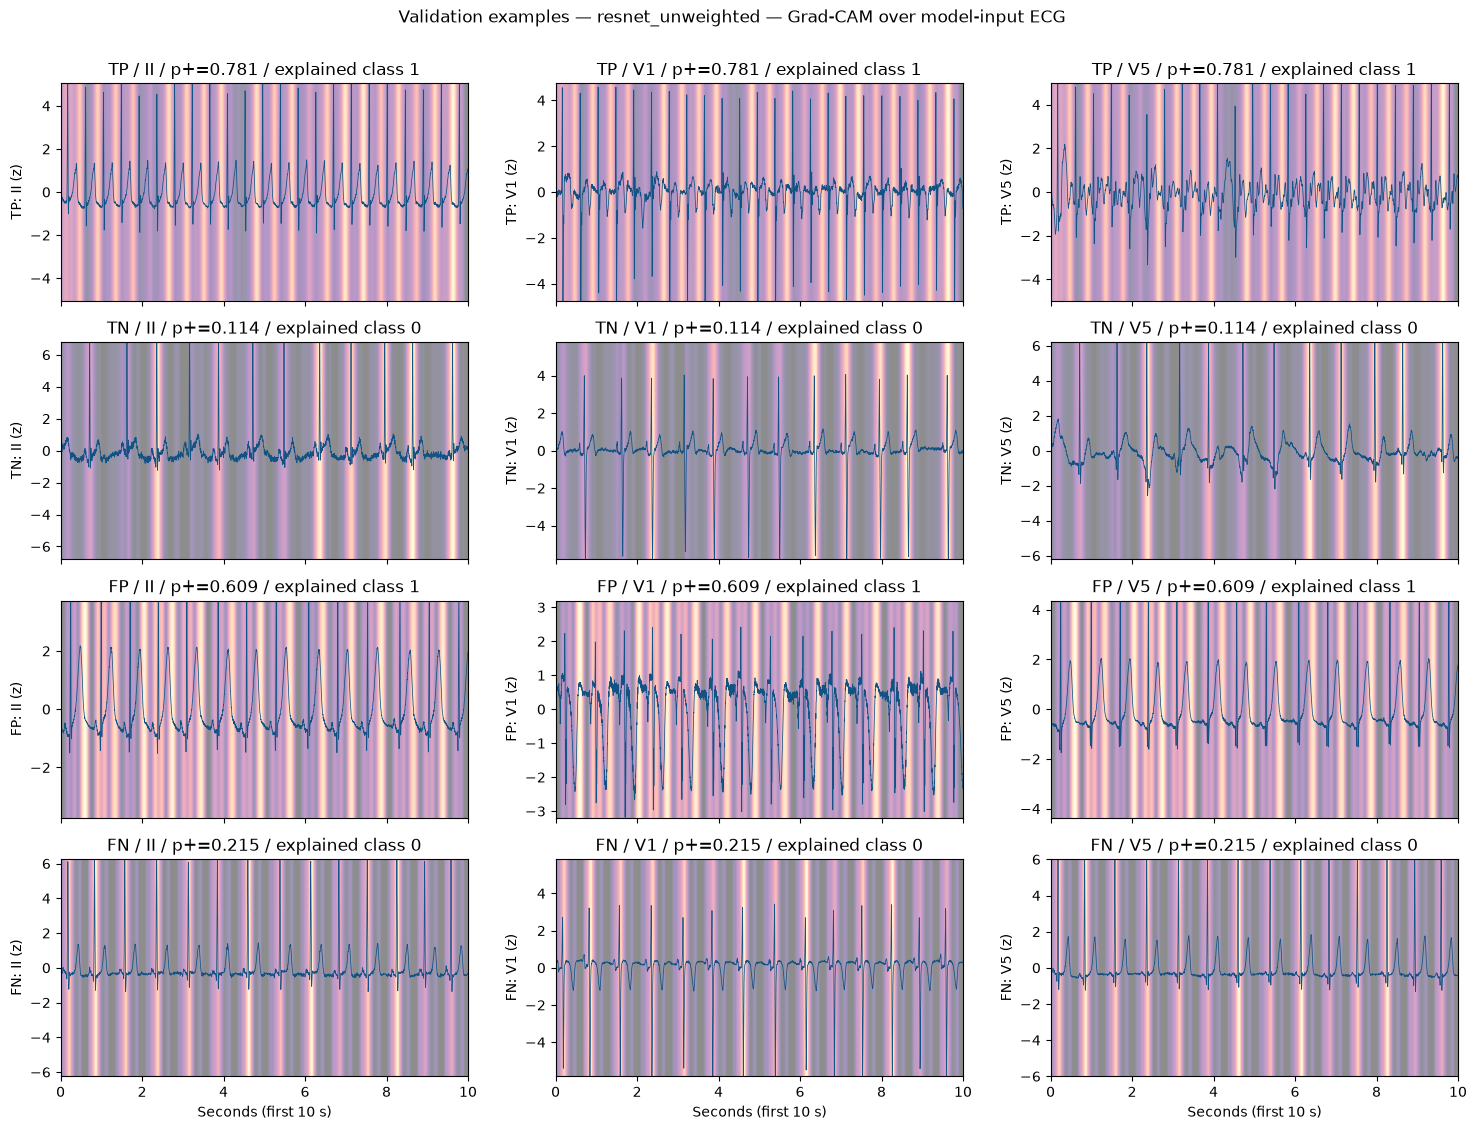

Saved /home/souhit/Documents/Research/Pediatric_ECG/NoteBooks/Week5/disease_labelled/gradcam_outcomes.png


In [10]:
shown_leads=['II','V1','V5'];time=np.arange(N_SAMPLES)/FS
fig,axs=plt.subplots(len(examples),len(shown_leads),figsize=(15,2.8*len(examples)),sharex=True)
axs=np.atleast_2d(axs)
for row,(cat,e) in enumerate(examples.items()):
    for col,lead in enumerate(shown_leads):
        ax=axs[row,col];s=e['x'][LEAD_INDEX[lead]]
        ylim=max(3.2,np.percentile(abs(s),99)*1.1)
        ax.imshow(e['cam'][None,:],extent=(0,10,-ylim,ylim),aspect='auto',cmap='magma',alpha=.45,vmin=0,vmax=1)
        ax.plot(time,s,color='#125284',lw=.55)
        ax.set(xlim=(0,10),ylim=(-ylim,ylim),ylabel=f'{cat}: {lead} (z)',
               title=f'{cat} / {lead} / p+={e["p"]:.3f} / explained class {e["cls"]}')
        if row==len(examples)-1:ax.set_xlabel('Seconds (first 10 s)')
fig.suptitle(f'Validation examples — {selected} — Grad-CAM over model-input ECG',y=1.005)
plt.tight_layout();cam_path=OUT/'gradcam_outcomes.png';fig.savefig(cam_path,dpi=170,bbox_inches='tight');plt.show()
print('Saved',cam_path)

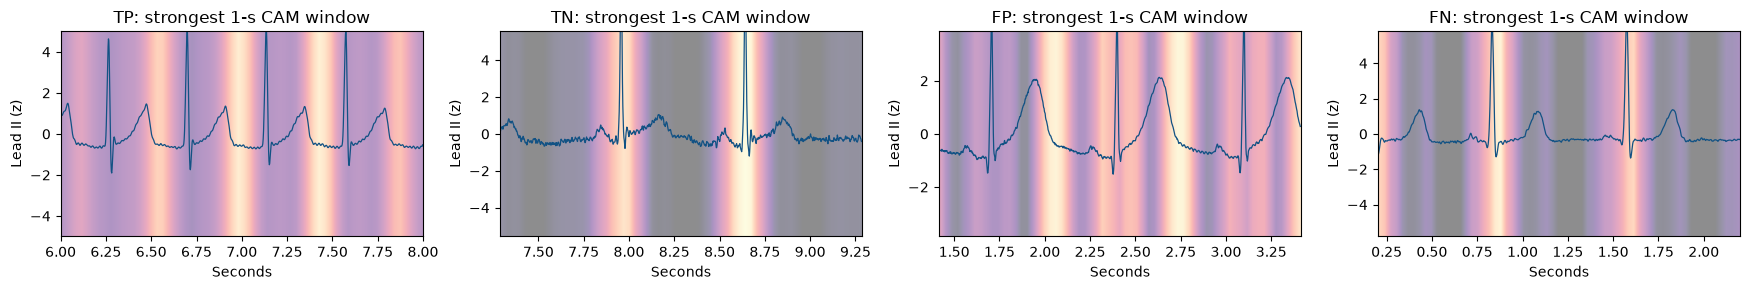

Saved /home/souhit/Documents/Research/Pediatric_ECG/NoteBooks/Week5/disease_labelled/gradcam_leadII_zooms.png


In [11]:
fig,axs=plt.subplots(1,len(examples),figsize=(4.4*len(examples),3),squeeze=False)
for ax,(cat,e) in zip(axs[0],examples.items()):
    center=float(np.argmax(np.convolve(e['cam'],np.ones(FS)/FS,mode='valid'))/FS+.5)
    start=max(0,min(8,center-1));stop=start+2
    start_i=int(start*FS);stop_i=int(stop*FS)
    s=e['x'][LEAD_INDEX['II']];ymax=max(3.2,np.percentile(abs(s[start_i:stop_i]),99)*1.1)
    ax.imshow(e['cam'][None,start_i:stop_i],extent=(start,stop,-ymax,ymax),aspect='auto',
              cmap='magma',alpha=.45,vmin=0,vmax=1)
    ax.plot(time[start_i:stop_i],s[start_i:stop_i],color='#125284',lw=.9)
    ax.set(xlim=(start,stop),ylim=(-ymax,ymax),xlabel='Seconds',ylabel='Lead II (z)',
           title=f'{cat}: strongest 1-s CAM window')
plt.tight_layout();zoom_path=OUT/'gradcam_leadII_zooms.png';fig.savefig(zoom_path,dpi=180,bbox_inches='tight');plt.show()
print('Saved',zoom_path)

## Interpretation boundary

The tables and overlays above show **where the selected model's class score is sensitive in these four validation examples**. A bright span is a model-specific temporal attribution at the layer's resolution, displayed over multiple leads for context; it is not evidence that any particular lead or waveform component caused disease. Selection by median score avoids visual cherry-picking, but four examples cannot describe the full error distribution. Stronger evidence would require systematic localization and perturbation checks, age/phenotype stratification, independent labels, and clinical review. Grad-CAM depends on architecture and the chosen layer; its coarse and ReLU-clipped map can omit negative evidence. The first-window protocol ignores later ECG content. These images must not be read as clinical diagnoses.

## Post-selection confound and subgroup audit

The nine-lead acquisition configuration is strongly associated with the selected-code label in the train/validation cohort. This could allow a CNN to exploit lead availability as a shortcut. The next cell evaluates the selected ECG model within lead and age strata and fits simple **metadata-only** logistic models using training patients, then evaluates them on the same validation patients. This is a context check, not proof that the ECG model has or has not learned morphology. We do not access reserved patients. The selected ECG checkpoint remains fixed during this audit.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Re-load the selected checkpoint for a reproducible post-selection audit.
audit_model=ResNet1D(num_classes=2).to(DEVICE)
audit_saved=torch.load(OUT/'resnet_unweighted_best.pth',map_location=DEVICE,weights_only=False)
audit_model.load_state_dict(audit_saved['model_state_dict']);audit_model.eval()
_,audit_y,audit_p,_=run_epoch(audit_model,val_loader)
assert (metrics(audit_y,audit_p)['tn'],metrics(audit_y,audit_p)['fp'],
        metrics(audit_y,audit_p)['fn'],metrics(audit_y,audit_p)['tp'])==(1511,75,323,260)

val_age=val_df.Age.str.extract(r'^(\d+)d$')[0].astype(float).to_numpy()/365.25
train_age=train_df.Age.str.extract(r'^(\d+)d$')[0].astype(float).to_numpy()/365.25
assert np.isfinite(val_age).all() and np.isfinite(train_age).all()
val_lead9=(val_df.Lead==9).astype(int).to_numpy()
train_lead9=(train_df.Lead==9).astype(int).to_numpy()
metadata_scores={}
for name,xtrain,xval in [('lead_count_only',train_lead9[:,None],val_lead9[:,None]),
                         ('age_plus_lead_count',np.c_[train_age,train_lead9],np.c_[val_age,val_lead9])]:
    predictor=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
    predictor.fit(xtrain,train_df.target.to_numpy())
    metadata_scores[name]=predictor.predict_proba(xval)[:,1]

context=[]
for name,p in [('Week 4 ECG CNN',base_p),('Selected ECG ResNet',audit_p),*metadata_scores.items()]:
    m=metrics(audit_y,p)
    context.append(dict(model=name,accuracy=m['accuracy'],sensitivity=m['sensitivity'],
                        specificity=m['specificity'],auroc=m['auroc'],average_precision=m['average_precision']))
display(pd.DataFrame(context).set_index('model').round(4))

strata=[]
for group,mask in [('9 leads',val_df.Lead.to_numpy()==9),('12 leads',val_df.Lead.to_numpy()==12),
                   ('age <2y',val_age<2),('age 2–<6y',(val_age>=2)&(val_age<6)),
                   ('age 6–<12y',(val_age>=6)&(val_age<12)),('age >=12y',val_age>=12)]:
    y=audit_y[mask];p=audit_p[mask];m=metrics(y,p)
    strata.append(dict(group=group,n=len(y),positives=int(y.sum()),prevalence=y.mean(),
                       sensitivity=m['sensitivity'],specificity=m['specificity'],
                       auroc=m['auroc'],average_precision=m['average_precision'],
                       tp=m['tp'],fn=m['fn']))
display(pd.DataFrame(strata).set_index('group').round(4))
print('These subgroup estimates are descriptive, share the model-selection validation set, and may be imprecise for small groups.')

,accuracy,sensitivity,specificity,auroc,average_precision
model,,,,,
Week 4 ECG CNN,0.7446,0.3122,0.9035,0.6763,0.4574
Selected ECG ResNet,0.8165,0.4460,0.9527,0.8144,0.6923
lead_count_only,0.7312,0.0000,1.0000,0.5956,0.3469
age_plus_lead_count,0.7363,0.1407,0.9552,0.7071,0.4570


,n,positives,prevalence,sensitivity,specificity,auroc,average_precision,tp,fn
group,,,,,,,,,
9 leads,281,157,0.5587,0.7261,0.7742,0.8263,0.8679,114,43
12 leads,1888,426,0.2256,0.3427,0.9679,0.7869,0.6076,146,280
age <2y,272,145,0.5331,0.6552,0.8425,0.8400,0.8643,95,50
age 2–<6y,495,212,0.4283,0.4953,0.9329,0.8027,0.7908,105,107
age 6–<12y,802,136,0.1696,0.3456,0.9730,0.8184,0.5771,47,89
age >=12y,600,90,0.1500,0.1444,0.9647,0.6353,0.2734,13,77


These subgroup estimates are descriptive, share the model-selection validation set, and may be imprecise for small groups.


## Observed patterns, confounding, and limits

**Measured validation findings.** The unweighted ResNet has higher AP (0.6923 versus 0.4574), AUROC (0.8144 versus 0.6763), sensitivity (0.4460 versus 0.3122), and specificity (0.9527 versus 0.9035) than the preserved Week 4 checkpoint on the same records. The weighted ResNet increases sensitivity to 0.6672 at the fixed threshold, with lower specificity (0.7768) and AP (0.6548) than the selected unweighted model. These are single-seed, selection-set results, not independent confirmation of improvement.

The validation selected-code prevalence is 55.9% for nine-lead records and 22.6% for twelve-lead records. The selected model's sensitivity is 72.6% and 34.3% in those groups, respectively. Sensitivity is 14.4% in the age >=12 years group (13 of 90 positives found). The age-plus-lead-count metadata-only model reaches AP 0.4570, below the ECG ResNet's 0.6923. This suggests the ResNet uses information beyond those two simple metadata variables, but does **not** rule out other acquisition, age, or cohort shortcuts. The strong group differences require further study; subgroup estimates are descriptive and unconfirmed.

**Visual observations from four median-score examples.** Grad-CAM shows repeating bands over cardiac cycles. In the TP and FP examples, bright bands often occur near a broad deflection after a sharp spike in lead II; in TN and FN, some bright bands coincide with sharp spikes. These are temporal patterns in four selected records, not evidence that the network recognizes a named waveform component or a disease mechanism. The FP resembles the TP in its repeated positive-class pattern; the FN also has conspicuous repeated deflections. The same CAM is plotted over II, V1, and V5 because the chosen convolutional layer mixes leads. The figure cannot identify lead-specific importance.

The maps may be visually suggestive of ECG-timed model activity, but visual appearance alone does not validate an explanation. Grad-CAM is layer-dependent, coarse, and ReLU-clipped; it can omit negative evidence. This experiment uses only the first 10 seconds, per-lead z-scores remove absolute voltage, and selected-code absence is not equivalent to being disease-free. Independent clinical review, perturbation and parameter-sensitivity controls, subgroup replication, and a later prespecified test evaluation are needed before claiming clinically meaningful features or utility. The frozen test set remains untouched.